# Actividad de Evaluación 1 – Unidad II
## Exploración y diagnóstico del conjunto de datos

**Materia:** Extracción de Conocimiento en Bases de Datos · Recursamiento 2026  
**Alumno:** José Gamaliel Potenciano Méndez  
**Proyecto:** Análisis y predicción de calidad del aire  
**Dataset:** Air Quality · UCI Machine Learning Repository  

Este notebook realiza únicamente exploración y diagnóstico. El archivo original se lee sin modificar. No se eliminan filas, no se reemplazan valores y no se entrenan modelos.

## 1. Carga e identificación del dataset

Se utilizará Pandas para leer el CSV original. El separador es `;` y la coma decimal se convierte durante la lectura. El valor `-200` se conserva en esta primera carga para poder identificarlo como marcador especial de faltantes.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CSV = ROOT / 'data' / 'raw' / 'air+quality' / 'AirQualityUCI.csv'
df = pd.read_csv(CSV, sep=';', decimal=',', encoding='latin1')
df = df.iloc[:, :15]
print('Archivo:', CSV)
print('Filas y columnas:', df.shape)


Archivo: C:\REC_ECBD_2026_PotencianoMendex_JoseGamaliel\data\raw\air+quality\AirQualityUCI.csv
Filas y columnas: (9471, 15)


**Interpretación:** el dataset Air Quality contiene registros horarios de contaminantes, respuestas instrumentales y condiciones ambientales. El archivo original permanece en `data/raw/`.

## 2. Exploración inicial con Pandas

In [2]:
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


`head()` muestra las primeras filas y permite comprobar que las columnas y los valores se cargaron correctamente.

In [3]:
df.shape

(9471, 15)

`shape` devuelve el número de filas y columnas. Las filas físicas incluyen espacios finales del archivo, por lo que se revisarán junto con los valores vacíos.

In [4]:
df.columns.tolist()

['Date',
 'Time',
 'CO(GT)',
 'PT08.S1(CO)',
 'NMHC(GT)',
 'C6H6(GT)',
 'PT08.S2(NMHC)',
 'NOx(GT)',
 'PT08.S3(NOx)',
 'NO2(GT)',
 'PT08.S4(NO2)',
 'PT08.S5(O3)',
 'T',
 'RH',
 'AH']

`columns` muestra los nombres reales de las variables y evita inventar campos que no existen.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), str(2)
memory usage: 1.1 MB


`info()` muestra tipos generales y valores no nulos. Date y Time llegan como texto y podrán convertirse a fecha-hora en una etapa posterior.

In [6]:
df.dtypes

Date                 str
Time                 str
CO(GT)           float64
PT08.S1(CO)      float64
NMHC(GT)         float64
C6H6(GT)         float64
PT08.S2(NMHC)    float64
NOx(GT)          float64
PT08.S3(NOx)     float64
NO2(GT)          float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
T                float64
RH               float64
AH               float64
dtype: object

`dtypes` confirma el tipo que Pandas asignó a cada columna. Las mediciones se cargan como numéricas y Date/Time como object.

In [7]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,9357,391,11/03/2004,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9357,24,18.00.00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),9357.0,NaN,NaN,NaN,-34.207524,77.65717,-200.0,0.6,1.5,2.6,11.9
PT08.S1(CO),9357.0,NaN,NaN,NaN,1048.990061,329.83271,-200.0,921.0,1053.0,1221.0,2040.0
NMHC(GT),9357.0,NaN,NaN,NaN,-159.090093,139.789093,-200.0,-200.0,-200.0,-200.0,1189.0
C6H6(GT),9357.0,NaN,NaN,NaN,1.865683,41.380206,-200.0,4.0,7.9,13.6,63.7
PT08.S2(NMHC),9357.0,NaN,NaN,NaN,894.595276,342.333252,-200.0,711.0,895.0,1105.0,2214.0
NOx(GT),9357.0,NaN,NaN,NaN,168.616971,257.433866,-200.0,50.0,141.0,284.0,1479.0
PT08.S3(NOx),9357.0,NaN,NaN,NaN,794.990168,321.993552,-200.0,637.0,794.0,960.0,2683.0
NO2(GT),9357.0,NaN,NaN,NaN,58.148873,126.940455,-200.0,53.0,96.0,133.0,340.0


`describe()` resume las variables. En esta actividad se usa solo para conocer rangos y cantidades; no se modifica el dataset.

## 3. Diccionario y clasificación de variables

In [8]:
diccionario = pd.DataFrame({
 'Variable': df.columns,
 'Tipo Python': [str(df[c].dtype) for c in df.columns],
 'Tipo de variable': ['Temporal','Temporal','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua','Cuantitativa continua'],
 'Unidad o significado': ['Fecha','Hora','CO de referencia (mg/m³)','Respuesta sensor CO','NMHC de referencia (µg/m³)','Benceno (µg/m³)','Respuesta sensor NMHC','NOx de referencia (ppb)','Respuesta sensor NOx','NO2 de referencia (µg/m³)','Respuesta sensor NO2','Respuesta sensor O3','Temperatura (°C)','Humedad relativa (%)','Humedad absoluta'],
 'Utilidad propuesta': ['Orden temporal','Orden temporal','Objetivo de regresión','Entrada candidata','Contexto','Contexto','Entrada candidata','Contexto','Entrada candidata','Contexto','Entrada candidata','Entrada candidata','Entrada candidata','Entrada candidata','Entrada candidata']
})
diccionario

,Variable,Tipo Python,Tipo de variable,Unidad o significado,Utilidad propuesta
0,Date,str,Temporal,Fecha,Orden temporal
1,Time,str,Temporal,Hora,Orden temporal
2,CO(GT),float64,Cuantitativa continua,CO de referencia (mg/m³),Objetivo de regresión
3,PT08.S1(CO),float64,Cuantitativa continua,Respuesta sensor CO,Entrada candidata
4,NMHC(GT),float64,Cuantitativa continua,NMHC de referencia (µg/m³),Contexto
5,C6H6(GT),float64,Cuantitativa continua,Benceno (µg/m³),Contexto
6,PT08.S2(NMHC),float64,Cuantitativa continua,Respuesta sensor NMHC,Entrada candidata
7,NOx(GT),float64,Cuantitativa continua,NOx de referencia (ppb),Contexto
8,PT08.S3(NOx),float64,Cuantitativa continua,Respuesta sensor NOx,Entrada candidata
9,NO2(GT),float64,Cuantitativa continua,NO2 de referencia (µg/m³),Contexto


**Interpretación:** las variables GT son mediciones de referencia; las PT08 son respuestas instrumentales; T, RH y AH describen el ambiente. CO(GT) es una posible variable objetivo numérica.

## 4. Tipo y fuente de los datos

El dataset procede del **UCI Machine Learning Repository**. Es un archivo tabular estructurado en formato CSV/XLSX. Contiene datos generados por instrumentos de medición y sensores, acompañados por fechas, horas y mediciones de referencia. No es un conjunto de redes sociales ni de transacciones.

## 5. Diagnóstico de calidad

### 5.1 Valores faltantes

In [9]:
missing_marker = (df == -200).sum()
missing_empty = df.isna().sum()
missing = pd.DataFrame({'Marcador -200': missing_marker, 'Celdas vacías': missing_empty})
missing['Total identificado'] = missing.sum(axis=1)
missing['Porcentaje sobre filas'] = (missing['Total identificado'] / len(df) * 100).round(2)
missing

,Marcador -200,Celdas vacías,Total identificado,Porcentaje sobre filas
Date,0,114,114,1.20
Time,0,114,114,1.20
CO(GT),1683,114,1797,18.97
PT08.S1(CO),366,114,480,5.07
NMHC(GT),8443,114,8557,90.35
C6H6(GT),366,114,480,5.07
PT08.S2(NMHC),366,114,480,5.07
NOx(GT),1639,114,1753,18.51
PT08.S3(NOx),366,114,480,5.07
NO2(GT),1642,114,1756,18.54


**Interpretación:** `-200` es un marcador documentado por UCI para valores faltantes. En esta actividad no se convierte ni elimina; solo se cuantifica. En la siguiente etapa se podrá tratar en una copia.

### 5.2 Registros duplicados

In [10]:
duplicados = int(df.duplicated().sum())
print('Registros duplicados:', duplicados)

Registros duplicados: 113


**Interpretación:** un duplicado puede deberse a una repetición de la captura o a una fila repetida durante la descarga. No se elimina en esta actividad; se revisaría antes de preparar los datos.

### 5.3 Inconsistencias y posibles valores incorrectos

In [11]:
print('Valores negativos en variables numéricas (sin contar -200):')
num = df.select_dtypes(include='number')
print(((num < 0) & (num != -200)).sum())
print('Fechas que Pandas no puede interpretar:', pd.to_datetime(df['Date'], dayfirst=True, errors='coerce').isna().sum())
print('Horas que Pandas no puede interpretar:', pd.to_datetime(df['Time'].astype(str).str.replace('.', ':', regex=False), format='%H:%M:%S', errors='coerce').isna().sum())

Valores negativos en variables numéricas (sin contar -200):
CO(GT)            0
PT08.S1(CO)       0
NMHC(GT)          0
C6H6(GT)          0
PT08.S2(NMHC)     0
NOx(GT)           0
PT08.S3(NOx)      0
NO2(GT)           0
PT08.S4(NO2)      0
PT08.S5(O3)       0
T                13
RH                0
AH                0
dtype: int64
Fechas que Pandas no puede interpretar: 114
Horas que Pandas no puede interpretar: 114


**Interpretación:** los valores `-200` se separan conceptualmente de los valores físicos. Las fechas y horas deben convertirse y validarse en la preparación. Los extremos numéricos no se eliminan automáticamente: pueden ser mediciones reales o problemas de sensor y requieren revisión.

## 6. Análisis estadístico inicial

In [12]:
seleccion = ['CO(GT)', 'NO2(GT)', 'T', 'RH', 'AH']
estadistica = df[seleccion].replace(-200, np.nan).describe().T[['mean','50%','min','max','std']].rename(columns={'mean':'Media','50%':'Mediana','min':'Mínimo','max':'Máximo','std':'Desviación estándar'}).round(3)
estadistica

,Media,Mediana,Mínimo,Máximo,Desviación estándar
CO(GT),2.153,1.800,0.100,11.900,1.453
NO2(GT),113.091,109.000,2.000,340.000,48.370
T,18.318,17.800,-1.900,44.600,8.832
RH,49.234,49.600,9.200,88.700,17.317
AH,1.026,0.995,0.185,2.231,0.404


**Interpretación:** CO y NO2 representan contaminantes de referencia; T, RH y AH describen el ambiente. La diferencia entre media y mediana ayuda a detectar distribuciones asimétricas y posibles valores extremos.

## 7. Detección inicial de valores atípicos

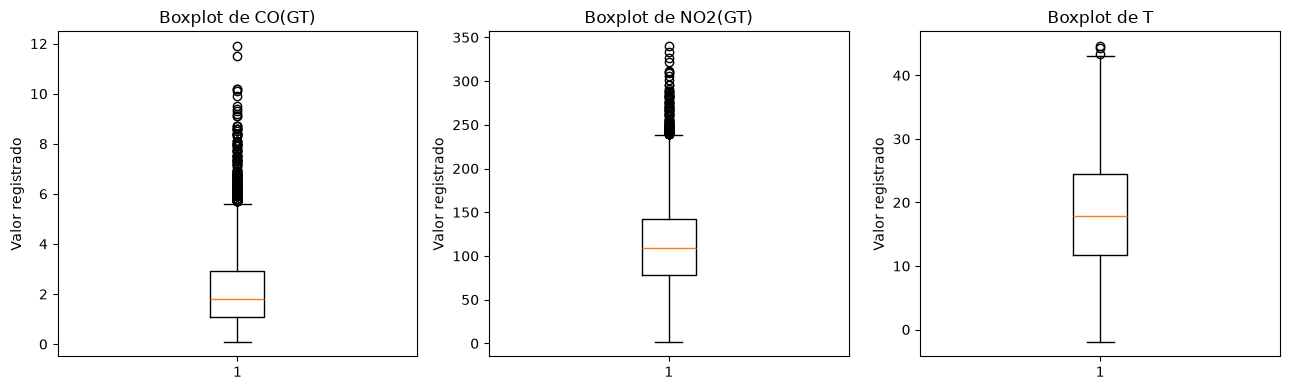

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ['CO(GT)', 'NO2(GT)', 'T']):
    ax.boxplot(df[col].replace(-200, np.nan).dropna())
    ax.set_title(f'Boxplot de {col}')
    ax.set_ylabel('Valor registrado')
plt.tight_layout()
plt.savefig(ROOT / 'docs' / 'figuras_u2' / 'boxplots.png', dpi=150)
plt.show()

**Interpretación:** los puntos alejados del centro se consideran candidatos a atípicos. No se eliminan porque pueden representar episodios reales de contaminación o lecturas instrumentales que deben verificarse con fecha, hora y contexto.

## 8. Visualizaciones iniciales

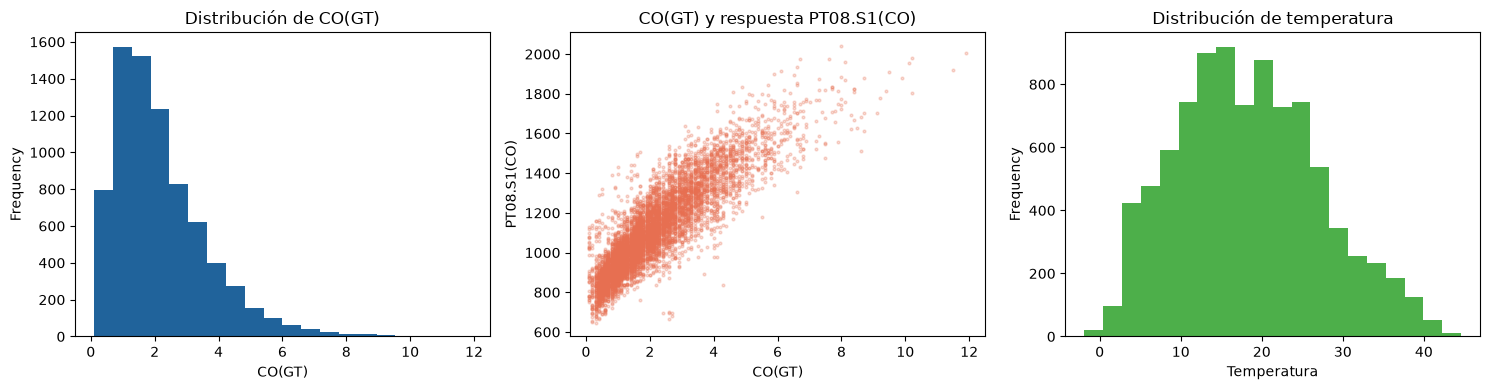

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['CO(GT)'].replace(-200, np.nan).dropna().plot.hist(ax=axes[0], bins=20, title='Distribución de CO(GT)', color='#20639b')
axes[0].set_xlabel('CO(GT)')
axes[1].scatter(df['CO(GT)'].replace(-200, np.nan), df['PT08.S1(CO)'].replace(-200, np.nan), s=4, alpha=.25, color='#e76f51')
axes[1].set_title('CO(GT) y respuesta PT08.S1(CO)'); axes[1].set_xlabel('CO(GT)'); axes[1].set_ylabel('PT08.S1(CO)')
df['T'].replace(-200, np.nan).plot.hist(ax=axes[2], bins=20, title='Distribución de temperatura', color='#4daf4a'); axes[2].set_xlabel('Temperatura')
plt.tight_layout()
plt.savefig(ROOT / 'docs' / 'figuras_u2' / 'exploracion_inicial.png', dpi=150)
plt.show()

**Interpretación:** el histograma muestra la distribución de CO; la dispersión permite observar visualmente la relación entre CO y el sensor S1; el segundo histograma resume la temperatura. Son relaciones exploratorias y no prueban causalidad.

## 9. Propuestas para análisis posteriores

- **Regresión:** usar CO(GT) como objetivo numérico; como entradas candidatas, las cinco respuestas PT08, T, RH y AH.
- **Clasificación:** crear posteriormente bandas académicas de CO (baja, media y alta). Las bandas no son una norma sanitaria.
- **Agrupamiento:** usar las cinco respuestas PT08 junto con T, RH y AH para buscar grupos de comportamiento sensorial y ambiental.

Estas propuestas se relacionan con el problema de la Unidad I: entender si las señales instrumentales y el ambiente ayudan a estudiar la concentración de CO.

## 10. Conclusión del diagnóstico

El dataset contiene mediciones horarias de contaminantes, respuestas instrumentales y condiciones ambientales. Su estructura es tabular y permite continuar con el proyecto, pero presenta valores faltantes codificados como `-200`, posibles registros duplicados, fechas y horas que deben validarse y valores extremos que no deben eliminarse sin revisión. Las variables requieren tratamiento en una copia posterior. En esta actividad no se modificó el original. El siguiente paso será la limpieza, transformación y ETL de la Unidad II.